# Circle: a ring-shaped posterior (2-D)

The target is

$$\pi(\theta)\;\propto\;\exp\!\Big(-\tfrac12 F(\theta)^2\Big),\qquad
F(\theta)=\frac{1-(\theta_1^2+\theta_2^2)}{0.3},\qquad \theta\in\mathbb R^2 .$$

Its mass lies on a thin ring around the unit circle. The methods are compared on the total
variation (TV) against a grid reference, the reverse KL, the ESS, and MMD and entropic $W_2$
against exact target samples.

Each method fits a mixture of $K=40$ components for 500 iterations from a shared
initialisation. The settings are in `configs/Circle.toml`.

In [1]:
%matplotlib inline
# Figures are embedded in the notebook as PNG (displayed) and vector PDF; none is written to disk.
%config InlineBackend.figure_formats = ["png", "pdf"]
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "1")
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

from gmmvi import benchmark, metrics, plotting

GROUP   = "Circle"                      # configs/Circle.toml <-> results/Circle.npz
CFG     = benchmark.load_config(GROUP)



## 1. The target

`registry.build` returns the target together with a $160\times160$ evaluation grid and the
normalised reference density used for TV.

abcde_C: dim=2, grid (160, 160) on lims (-3, 3, -3, 3)  (C: Circle)


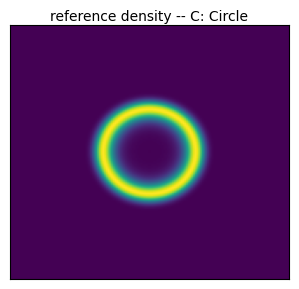

In [2]:
from gmmvi.targets import registry

spec = registry.build(CFG["target"])
print(f"{spec.name}: dim={spec.dim}, grid {spec.grid_shape} on lims {spec.lims}  "
      f"({spec.meta['case']})")

plotting.density_panel(spec, reference=True, figsize=(3.6, 3.3),
                       title=f"reference density -- {spec.meta['case']}")
plt.show()

## 2. The saved run

The next cell loads the stored results and prints what was saved with them: the mixture size,
the number of iterations, and each method's hyperparameters and runtime. `USE_SEEDS` selects
the seeds used throughout (`None` uses every stored seed). Every number reported later is a
mean over these seeds, with one standard deviation as the error bar.

In [3]:
USE_SEEDS = [0, 1, 2, 3, 4]

RESULTS = benchmark.require_results(GROUP)
STORED_SEEDS = sorted({s for _, s in RESULTS})
if USE_SEEDS is not None:
    missing = sorted(set(USE_SEEDS) - set(STORED_SEEDS))
    if missing:
        raise SystemExit(f"USE_SEEDS asks for {missing}, not in results/{GROUP}.npz ({STORED_SEEDS})")
    RESULTS = {(m, s): r for (m, s), r in RESULTS.items() if s in USE_SEEDS}
SEEDS   = sorted({s for _, s in RESULTS})
METHODS = [m for m in ["gmbbvi", "semtrux", "ibw", "WFR"] if any(k[0] == m for k in RESULTS)]
GROUPED = benchmark.group_seeds(RESULTS, METHODS)

SPREAD       = "std"
SPREAD_LABEL = rf"mean $\pm$ 1 s.d. over {len(SEEDS)} seeds"
SEED    = SEEDS[0]
RES     = {m: GROUPED[m][SEED] for m in METHODS}
K, N_ITER = RES[METHODS[0]].K, RES[METHODS[0]].n_iterations

print(f"loaded results/{GROUP}.npz: methods {METHODS}, run seeds {SEEDS}"
      + (f"  (of {len(STORED_SEEDS)} stored: {STORED_SEEDS})" if len(SEEDS) < len(STORED_SEEDS) else ""))
print("\nstored run provenance (the hyperparameters are shared by every seed):")
for m in METHODS:
    r  = RES[m]
    rt = np.mean([x.runtime_s for x in GROUPED[m].values()])
    hp = {k: r.hparams[k] for k in ("learning_rate", "dt_fr", "eta_max", "eta_mode",
                                    "update_hessian", "J", "BKL") if k in r.hparams}
    print(f"  {plotting.LABELS[m]:8s} K={r.K} n_iter={r.n_iterations}  "
          f"runtime {rt:6.1f}s (mean of {len(GROUPED[m])})  "
          f"{r.n_target_evals:>12,} target evals   {hp}")


loaded results/Circle.npz: methods ['gmbbvi', 'semtrux', 'ibw', 'WFR'], run seeds [0, 1, 2, 3, 4]  (of 15 stored: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14])

stored run provenance (the hyperparameters are shared by every seed):
  GMBBVI   K=40 n_iter=500  runtime    0.1s (mean of 5)       661,000 target evals   {'J': 8, 'BKL': 1000}
  SEMTRUX  K=40 n_iter=500  runtime    1.2s (mean of 5)       661,000 target evals   {'J': 8, 'BKL': 1000}
  IBW      K=40 n_iter=500  runtime    0.0s (mean of 5)       821,000 target evals   {'learning_rate': 0.002, 'BKL': 1000}
  WFR      K=40 n_iter=500  runtime    0.1s (mean of 5)       661,000 target evals   {'dt_fr': 0.25, 'eta_max': 0.002, 'eta_mode': 'adaptive', 'update_hessian': 'stein', 'J': 8, 'BKL': 1000}


## 3. The shared initialisation

Every method starts from the same mixture. The means are drawn from $\mathcal N(0,\,2^2 I)$
and the covariances are $10^{-5}I$.

init: 40 components, mean of means [-0.018 -0.104], std of means 2.01
      covariances = 1.0e-05 * I


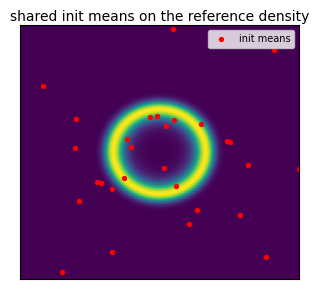

In [4]:
_logged = [m for m in METHODS if RES[m].means_log is not None]
m0 = RES[_logged[0]].means_log[0]
for m in _logged[1:]:
    assert np.allclose(RES[m].means_log[0], m0), f"{m} started from a different init?"
c0 = RES[_logged[0]].covs_log[0] if RES[_logged[0]].covs_log is not None else None
print("init: %d components, mean of means %s, std of means %.2f"
      % (len(m0), np.round(m0.mean(0), 3), m0.std()))
if c0 is not None:
    print("      covariances = %.1e * I" % c0[0, 0, 0])

ax = plotting.density_panel(spec, reference=True, figsize=(3.6, 3.3),
                            title="shared init means on the reference density")
ax.scatter(m0[:, 0], m0[:, 1], s=8, c="red", label="init means")
ax.legend(fontsize=7, loc="upper right")
plt.show()

## 5. Fitted densities

The reference density and each method's final mixture for seed `DENSITY_SEED`, with the TV to
the reference in each title.

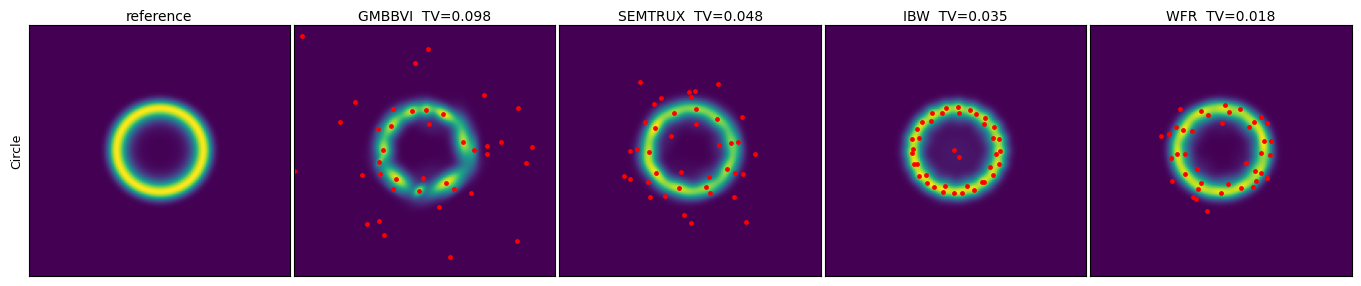

In [5]:
DENSITY_SEED = 1
_ALL = benchmark.group_seeds(benchmark.require_results(GROUP), METHODS)
RES_D = {m: _ALL[m][DENSITY_SEED] for m in METHODS}
TV = {m: metrics.total_variation(spec.grid_pts, spec.ref_density,
                                 RES_D[m].means, RES_D[m].covariances, RES_D[m].weights)
      for m in METHODS}
fig, axes = plotting.density_row(
    spec, RES_D, methods=METHODS,
    titles={m: f"{plotting.LABELS[m]}  TV={TV[m]:.3f}" for m in METHODS},
    ylabel="Circle")
plt.show()

## 5b. Reverse KL on a shared evaluator

Every stored snapshot is scored with the same random numbers for all methods, so iteration 0
agrees across methods and later differences come from the fits.

In [6]:
KL_ITERS, KLS = benchmark.kl_traces(GROUPED, spec=spec, config=CFG)

for m in METHODS:
    Y    = KLS[m]
    mean = np.nanmean(np.where(np.isfinite(Y), Y, np.nan), axis=0)
    print(f"{plotting.LABELS[m]:8s}: -ELBO {mean[0]:9.4f} -> {mean[-1]:8.4f}   ")
          

GMBBVI  : -ELBO  640.5399 ->  -0.8043   
SEMTRUX : -ELBO  640.5399 ->  -0.8524   
IBW     : -ELBO  640.5399 ->  -0.8461   
WFR     : -ELBO  640.5399 ->  -0.8575   


## 6. Quantitative summary

TV, ESS and weight entropy of the final mixtures, and the final $-\mathrm{ELBO}$ from section 5b. The
$-\mathrm{ELBO}$ is the reverse KL minus $\log Z$, so it can be negative.

C: Circle  (K=40, 500 iterations, seeds [0, 1, 2, 3, 4])
method                  tv            neg_elbo                ess     weight_entropy  runtime_s
-----------------------------------------------------------------------------------------------
GMBBVI   0.1001 +/- 0.0271  -0.8043 +/- 0.0384  0.8614 +/- 0.0742  0.6369 +/- 0.0294        0.1
SEMTRUX  0.0442 +/- 0.0063  -0.8524 +/- 0.0024  0.9810 +/- 0.0061  0.7054 +/- 0.0129        1.2
IBW      0.0317 +/- 0.0037  -0.8461 +/- 0.0124  0.9864 +/- 0.0045  1.0000 +/- 0.0000        0.0
WFR      0.0251 +/- 0.0079  -0.8575 +/- 0.0029  0.9939 +/- 0.0036  0.8109 +/- 0.0357        0.1


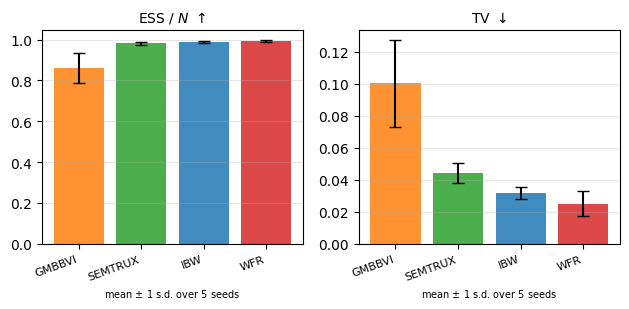

In [7]:
ROWS = {}
for m in METHODS:
    row = benchmark.evaluate_seeds(GROUPED[m], spec, CFG, spread=SPREAD)
    KLY = KLS[m]
    row.update(zip(("neg_elbo", "neg_elbo_std", "neg_elbo_n"),
                   benchmark.reduce_seeds(KLY[:, -1], SPREAD)))
    ROWS[m] = row

print(f"{spec.meta['case']}  (K={K}, {N_ITER} iterations, seeds {SEEDS})")
print(plotting.summary_table(ROWS, columns=["tv", "neg_elbo", "ess", "weight_entropy",
                                            "runtime_s"]))

plotting.metric_bars(ROWS, ["ess", "tv"], methods=METHODS, spread_label=SPREAD_LABEL,
                     figsize=(6.4, 3.2))
plt.tight_layout(); plt.show()

## 7. Convergence

The $-\mathrm{ELBO}$ from section 5b, shown every 10 iterations. The y-axis is symlog where the curve
goes negative.

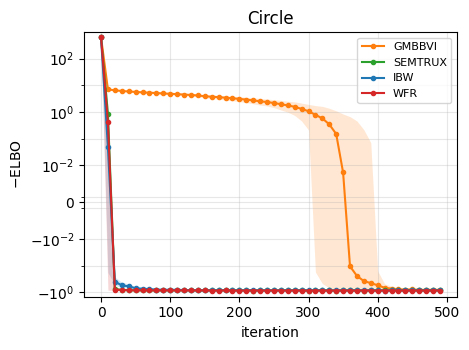

In [8]:
def thin_symlog_yticks(ax, every=2, gap=1.4):
    lo, hi = ax.get_ylim()
    ticks = [t for t in ax.get_yticks() if lo <= t <= hi]
    pos = sorted((t for t in ticks if t > 0), reverse=True)[::every]
    neg = sorted(t for t in ticks if t < 0)[::every]
    cand = ([0.0] if lo <= 0 <= hi else []) + sorted(pos + neg, key=lambda t: -abs(t))
    px = lambda t: ax.transData.transform((0.0, t))[1]
    min_px = gap * plt.rcParams["ytick.labelsize"] * ax.figure.dpi / 72 \
        if isinstance(plt.rcParams["ytick.labelsize"], (int, float)) else gap * 10 * ax.figure.dpi / 72
    kept = []
    for t in cand:
        if all(abs(px(t) - px(k)) >= min_px for k in kept):
            kept.append(t)
    ax.set_yticks(sorted(kept))
    ax.set_ylim(lo, hi)

_every10 = np.asarray(KL_ITERS) % 10 == 0
ax = plotting.trace_panel({m: (np.asarray(KL_ITERS)[_every10], KLS[m][:, _every10]) for m in METHODS},
                     ylabel=r"$-$ELBO",
                     title="Circle",
                     logy="auto", figsize=(4.8, 3.6), spread=SPREAD)
thin_symlog_yticks(ax)
plt.tight_layout(); plt.show()

## 8. Cost axis and the WALNUTS sampler

The x-axis is the number of target value-gradient pairs, which puts the VI methods and the
WALNUTS sampler on one scale. GMBBVI forms no gradient pairs and is left off. A chain has no
density, so the panels show MMD and entropic $W_2$ against exact target samples. The chain is
stored in `results/Circle__walnuts.npz`.

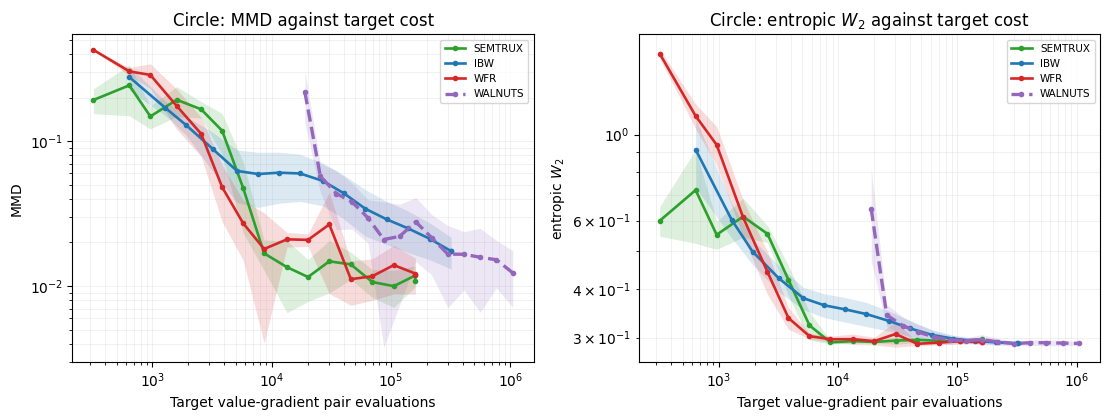

In [9]:
WAL      = "walnuts"
WAL_FILE  = benchmark.RESULTS_DIR / f"{GROUP}__walnuts.npz"
CURVE_PTS = 16              # log-spaced checkpoints per VI curve
CHAIN_CUTS = 14             # chain prefixes, log-spaced from end-of-warmup to full length
CURVE_SEEDS = SEEDS
_KC, _OC = CFG["metrics"]["mmd"], CFG["metrics"]["ot"]
MMD_N, MMD_SEED, MMD_TSEED = int(_KC["n"]), int(_KC["seed"]), int(_KC["target_seed"])
MMD_BIASED, OT_N, OT_SEED  = bool(_KC.get("biased", True)), int(_OC["n"]), int(_OC["seed"])
OT_TSEED, OT_MAXIT = int(_OC["target_seed"]), int(_OC.get("max_iterations", 20_000))
MMD_BW  = benchmark.mmd_bandwidth(spec, CFG)["bandwidth"]
OT_EPS  = benchmark.ot_epsilon(spec, CFG)["epsilon"]
CURVES  = [("mmd", "MMD", "log"), ("entropic_w2", r"entropic $W_2$", "log")]

from gmmvi.algorithms.walnuts import sampler as _wal_sampler

WGROUP = (benchmark.group_seeds(benchmark.load_results(GROUP, path=WAL_FILE), [WAL])
          if WAL_FILE.exists() else {})
if not WGROUP:
    print(f"{WAL_FILE.name} not found -- the sampler is absent from this section.")

_missing = sorted(set(CURVE_SEEDS) - set(SEEDS))
if _missing:
    raise SystemExit(f"CURVE_SEEDS asks for seeds {_missing}, which are not in results/{GROUP}.npz "
                     f"(it holds {SEEDS}). Run them, or narrow CURVE_SEEDS.")
GSEL = {m: {s: r for s, r in GROUPED[m].items() if s in CURVE_SEEDS} for m in METHODS}

def _score(m_=None, c_=None, w_=None, draws=None):
    return {"mmd": metrics.mmd(m_, c_, w_, spec.sample_fn, bandwidth=MMD_BW, n=MMD_N,
                               seed=MMD_SEED, target_seed=MMD_TSEED, biased=MMD_BIASED,
                               q_samples=draws),
            "entropic_w2": metrics.entropic_w2(m_, c_, w_, spec.sample_fn, OT_EPS, n=OT_N,
                                               seed=OT_SEED, target_seed=OT_TSEED,
                                               q_samples=draws, max_iterations=OT_MAXIT)[0]}

def _log_idx(n, k):
    return np.unique(np.geomspace(1, max(n - 1, 1), min(k, n - 1)).round().astype(int))

def _vi_curve(runs):
    """(x, {key: (n_seeds, n_pts)}) for one VI method, x = pairs, shared across seeds."""
    xs, ys = [], []
    for r in runs.values():
        if r.means_log is None or r.covs_log is None:
            return None
        pp  = r.hparams.get("J", r.hparams.get("BG"))
        idx = _log_idx(len(r.iters), CURVE_PTS)
        x   = [int(r.iters[i]) * r.K * pp for i in idx]
        row = [_score(r.means_log[i], r.covs_log[i], r.weights_log[i]) for i in idx]
        if x[-1] != benchmark.grad_evals(r):
            x.append(benchmark.grad_evals(r))
            row.append(_score(r.means, r.covariances, r.weights))
        xs.append(x); ys.append(row)
    n = min(len(x) for x in xs)
    return (np.array(xs[0][:n], float),
            {k: np.array([[p[k] for p in row[:n]] for row in ys], float) for k, _, _ in CURVES})

def _chain_curve(runs):
    xs, ys = [], []
    for r in runs.values():
        cum  = np.asarray(r.extra["evals_cumulative"], np.int64)
        warm = int(r.extra["n_target_evals_warmup"])
        raw  = dict(evals_cumulative=cum, draws=r.draws, n_iterations=int(r.n_iterations),
                    n_draws=len(r.draws), thin=1, n_target_evals=int(r.n_target_evals),
                    n_target_evals_warmup=warm)
        x, row = [], []
        for b in np.geomspace(max(warm * 1.05, 1), int(cum[-1]), CHAIN_CUTS):
            d, info = _wal_sampler.draws_at_budget(raw, int(b))
            if len(d) < 2:
                continue
            x.append(info["pairs_spent"])
            row.append(_score(draws=metrics.subsample(d, MMD_N, MMD_SEED)))
        xs.append(x); ys.append(row)
    n = min(len(x) for x in xs)
    return (np.mean([x[-n:] for x in xs], axis=0),
            {k: np.array([[p[k] for p in row[-n:]] for row in ys], float) for k, _, _ in CURVES})

CURVE_DATA, IS_CHAIN = {}, {}
for m in METHODS:
    if m == "gmbbvi":
        continue
    c = _vi_curve(GSEL[m])
    if c: CURVE_DATA[m], IS_CHAIN[m] = c, False
for m, grp in WGROUP.items():
    CURVE_DATA[m], IS_CHAIN[m] = _chain_curve(grp), True

fig, axes = plt.subplots(1, len(CURVES), figsize=(5.6 * len(CURVES), 4.3), squeeze=False)
for ax, (key, label, yscale) in zip(axes[0], CURVES):
    for name, (x, Y) in CURVE_DATA.items():
        if not np.isfinite(Y[key]).any():
            continue
        mu, sd = np.nanmean(Y[key], 0), np.nanstd(Y[key], 0)
        chain = IS_CHAIN[name]
        lab   = plotting.LABELS.get(name, name.upper())
        line, = ax.plot(x, mu, "--" if chain else "-", lw=2.4 if chain else 1.9,
                        marker="" if len(x) > 20 else "o", ms=3, label=lab,
                        color=plotting.method_color(name))
        ax.fill_between(x, mu - sd, mu + sd, alpha=0.16, lw=0, color=line.get_color())
    ax.set(xscale="log", xlabel=plotting.METRICS["n_grad_evals"].header,
           ylabel=label, title=f"{GROUP}: {label} against target cost")
    ax.set_yscale(yscale)
    ax.grid(alpha=0.3, which="both", lw=0.4); ax.legend(fontsize=7.5)
plt.tight_layout(); plt.show()